In [1]:

# Temel kütüphaneler
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Görüntü işleme
from PIL import Image

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

# Veri seti
from datasets import load_dataset

print("Kütüphaneler başarıyla yüklendi.")



Kütüphaneler başarıyla yüklendi.


In [ ]:

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA kullanılabilir:", torch.cuda.is_available())
print("Kullanılan cihaz:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU belleği:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")


PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA kullanılabilir: True
Kullanılan cihaz: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU belleği: 6.0 GB


In [ ]:


PROJECT_ROOT = r"C:\ReefSeg"


DATA_DIR = os.path.join(PROJECT_ROOT, "data")
RAW_DIR = os.path.join(DATA_DIR, "raw")
CACHE_DIR = os.path.join(RAW_DIR, "hf_cache")
METADATA_DIR = os.path.join(RAW_DIR, "metadata")

CLASS_MAPPING_PATH = os.path.join(
    METADATA_DIR, "class_mapping.json"
)


OUTPUT_DIR = os.path.join(PROJECT_ROOT, "outputs")


paths = {
    "Project": PROJECT_ROOT,
    "Dataset cache": CACHE_DIR,
    "Metadata": METADATA_DIR,
    "Class mapping": CLASS_MAPPING_PATH,
    "Outputs": OUTPUT_DIR
}

for name, path in paths.items():
    print(f"{name}: {'Mevcut' if os.path.exists(path) else 'Bulunamadı'}")


Project: Mevcut
Dataset cache: Mevcut
Metadata: Mevcut
Class mapping: Mevcut
Outputs: Mevcut


In [ ]:


with open(CLASS_MAPPING_PATH, "r", encoding="utf-8") as file:
    class_mapping = json.load(file)

fine_to_legacy = class_mapping["fine_to_legacy"]


fine_ids = set(map(int, fine_to_legacy.keys()))

legacy_ids = {
    info["legacy_id"]
    for info in fine_to_legacy.values()
}

print("Fine-grained sınıf sayısı:", len(fine_ids))
print("Legacy sınıf sayısı:", len(legacy_ids))
print("Legacy ID aralığı:", min(legacy_ids), "-", max(legacy_ids))

assert len(fine_ids) == 95
assert len(legacy_ids) == 39
assert legacy_ids == set(range(1, 40))

print("\nSınıf eşleştirmesi doğrulandı.")


Fine-grained sınıf sayısı: 95
Legacy sınıf sayısı: 39
Legacy ID aralığı: 1 - 39

Sınıf eşleştirmesi doğrulandı.


In [5]:
from datasets import load_dataset

dataset = load_dataset(
    "josauder/coralscapesV2",
    cache_dir=CACHE_DIR
)

In [7]:
print(dataset)
print("\nTrain:", len(dataset["train"]))
print("Validation:", len(dataset["validation"]))
print("Test:", len(dataset["test"]))

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 1790
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 170
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 473
    })
})

Train: 1790
Validation: 170
Test: 473


In [8]:
sample = dataset["train"][0]
image = sample["image"]
mask = sample["label"]
print("Görüntü boyutu:", image.size)
print("Görüntü modu:", image.mode)

print("Maske boyutu:", mask.size)
print("Maske modu:", mask.mode)
mask_array = np.array(mask)

print("Maskede bulunan sınıf ID'leri:")
print(np.unique(mask_array))

Görüntü boyutu: (2048, 1024)
Görüntü modu: RGB
Maske boyutu: (2048, 1024)
Maske modu: L
Maskede bulunan sınıf ID'leri:
[ 0 11 13 14 22 25 38 42 45 62 78 88]


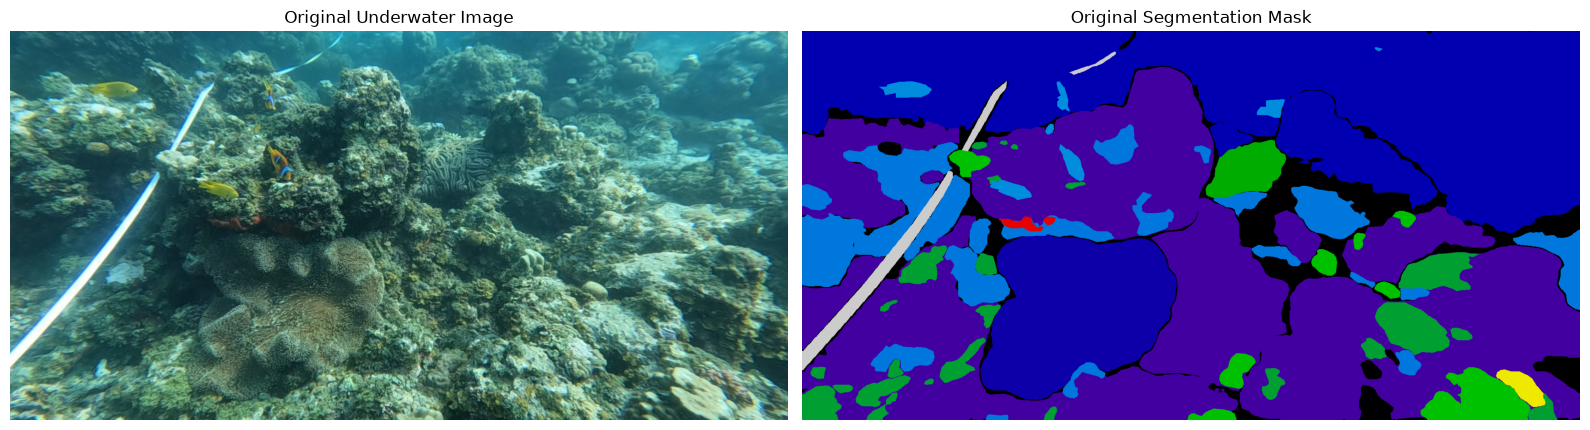

In [9]:
image_array = np.array(image)
mask_array = np.array(mask)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(image_array)
axes[0].set_title("Original Underwater Image")
axes[0].axis("off")

axes[1].imshow(mask_array, cmap="nipy_spectral")
axes[1].set_title("Original Segmentation Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [10]:
for fine_id, info in list(fine_to_legacy.items())[:10]:
    print(
        f"Fine ID: {fine_id} -> "
        f"Legacy ID: {info['legacy_id']} | "
        f"Class: {info['legacy_name']}"
    )

Fine ID: 1 -> Legacy ID: 1 | Class: crown of thorn
Fine ID: 2 -> Legacy ID: 2 | Class: acropora alive
Fine ID: 3 -> Legacy ID: 3 | Class: branching bleached
Fine ID: 4 -> Legacy ID: 4 | Class: branching dead
Fine ID: 5 -> Legacy ID: 5 | Class: algae covered substrate
Fine ID: 6 -> Legacy ID: 5 | Class: algae covered substrate
Fine ID: 7 -> Legacy ID: 5 | Class: algae covered substrate
Fine ID: 8 -> Legacy ID: 5 | Class: algae covered substrate
Fine ID: 9 -> Legacy ID: 5 | Class: algae covered substrate
Fine ID: 10 -> Legacy ID: 5 | Class: algae covered substrate


In [12]:
def convert_mask(mask):
    mask_array = np.array(mask)
    converted_mask = np.zeros_like(mask_array)

    for fine_id, info in fine_to_legacy.items():
        converted_mask[mask_array == int(fine_id)] = info["legacy_id"]

    return converted_mask

In [13]:
converted_mask = convert_mask(mask)

print("Orijinal sınıflar:", np.unique(mask_array))
print("Yeni sınıflar:", np.unique(converted_mask))
print("Orijinal maske boyutu:", mask_array.shape)
print("Yeni maske boyutu:", converted_mask.shape)

Orijinal sınıflar: [ 0 11 13 14 22 25 38 42 45 62 78 88]
Yeni sınıflar: [ 0  5  6  7  8 13 16 21 23 26 32 36]
Orijinal maske boyutu: (1024, 2048)
Yeni maske boyutu: (1024, 2048)


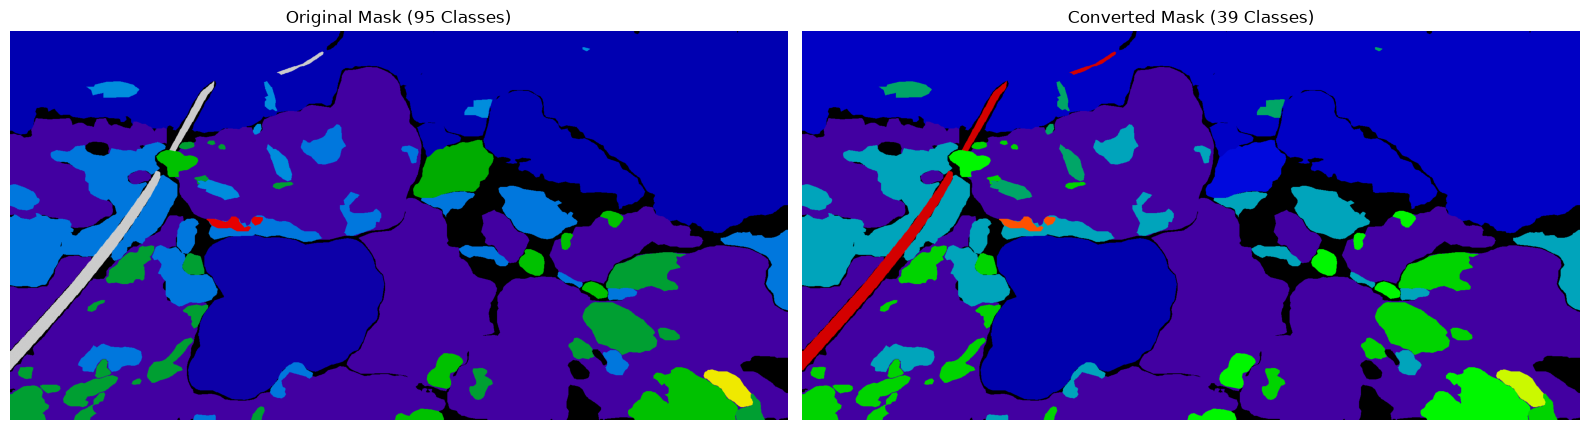

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(mask_array, cmap="nipy_spectral")
axes[0].set_title("Original Mask (95 Classes)")
axes[0].axis("off")

axes[1].imshow(converted_mask, cmap="nipy_spectral", vmin=0, vmax=39)
axes[1].set_title("Converted Mask (39 Classes)")
axes[1].axis("off")

plt.tight_layout()
plt.show()